Get what is needed from notebook 42 annoatation 

Import packages 

In [1]:
%pip install -q scanpy igraph celltypist


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Hide harmless warning messages.
# This line must come before the other imports.
import warnings
warnings.filterwarnings('ignore')

# Packages for numbers, tables and plots.
import numpy
import pandas
import matplotlib.pyplot

# Packages for single-cell analysis.
import scanpy
import celltypist

# Make the plots a bit smaller, with a white background.
scanpy.settings.set_figure_params(dpi=80, figsize=(4, 4), facecolor='white')

In [3]:
# version() tells us which version of a package is installed.
from importlib.metadata import version

print('scanpy     version:', version('scanpy'))
print('celltypist version:', version('celltypist'))
print('anndata    version:', version('anndata'))

scanpy     version: 1.12.4
celltypist version: 1.7.1
anndata    version: 0.13.4


download data

In [4]:
# Download the PBMC3k data (about 6 MB).
adata = scanpy.datasets.pbmc3k()

# Some genes share the same name. Make every name unique.
adata.var_names_make_unique()

# Print a summary: number of cells x number of genes.
print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)


normalise and log

In [5]:
# Scale every cell to a total of 10,000 counts.
scanpy.pp.normalize_total(adata, target_sum=1e4)

# Take log(1 + x) of every value.
scanpy.pp.log1p(adata)

Leiden clustering 

In [8]:
# Neighbor graph: connect each cell to its 10 most similar cells.
scanpy.pp.neighbors(adata, n_neighbors=10, n_pcs=40)

# UMAP: a 2D picture of the graph.
scanpy.tl.umap(adata)

# Leiden clustering of the graph.
scanpy.tl.leiden(
    adata,
    resolution=0.7,
    flavor='igraph',
    n_iterations=2,
    directed=False
)

manual label 

In [6]:
# One score per population, based on its marker genes.
# Each line adds a new column to adata.obs.
scanpy.tl.score_genes(adata, ['IL7R', 'CD3D'], score_name='CD4 T')
scanpy.tl.score_genes(adata, ['CD8A', 'CD8B'], score_name='CD8 T')
scanpy.tl.score_genes(adata, ['GNLY', 'NKG7'], score_name='NK')
scanpy.tl.score_genes(adata, ['MS4A1', 'CD79A'], score_name='B')
scanpy.tl.score_genes(adata, ['CD14', 'LYZ'], score_name='CD14 Mono')
scanpy.tl.score_genes(adata, ['FCGR3A', 'MS4A7'], score_name='FCGR3A Mono')
scanpy.tl.score_genes(adata, ['FCER1A', 'CST3'], score_name='DC')
scanpy.tl.score_genes(adata, ['PPBP', 'PF4'], score_name='Platelets')

In [9]:
# The names of the 8 score columns we just made.
populations = ['CD4 T', 'CD8 T', 'NK', 'B',
               'CD14 Mono', 'FCGR3A Mono', 'DC', 'Platelets']

# Average score of each population, in each cluster.
# Rows = clusters, columns = populations.
average_scores = adata.obs.groupby('leiden')[populations].mean()

# For each cluster, the population with the highest average score.
best_population = average_scores.idxmax(axis=1)

print(best_population)

leiden
0             NK
1          CD4 T
2              B
3      CD14 Mono
4             NK
5    FCGR3A Mono
6          CD4 T
7             DC
8      Platelets
dtype: str


... storing 'manual_label' as categorical


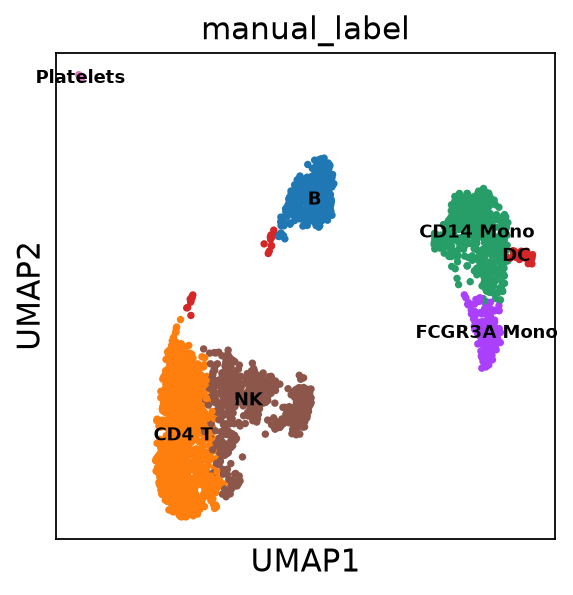

In [10]:
# Write the label of its cluster into every cell.
adata.obs['manual_label'] = adata.obs['leiden'].map(best_population)

# If you disagree with a label, change it here. Example:
# adata.obs.loc[adata.obs['leiden'] == '3', 'manual_label'] = 'CD8 T'

scanpy.pl.umap(adata, color='manual_label', legend_loc='on data', legend_fontsize=8)

celltypist

In [11]:
# Download the two immune models.
celltypist.models.download_models(model=['Immune_All_Low.pkl', 'Immune_All_High.pkl'])

# Load the fine-grained model into the variable 'model'.
model = celltypist.models.Model.load('Immune_All_Low.pkl')

print(model)

📜 Retrieving model list from server https://celltypist.cog.sanger.ac.uk/models/models.json
📚 Total models in list: 61
📂 Storing models in /home/lenovo/.celltypist/data/models
💾 Total models to download: 2
💾 Downloading model [1/2]: Immune_All_Low.pkl
💾 Downloading model [2/2]: Immune_All_High.pkl


CellTypist model with 98 cell types and 6639 features
    date: 2022-07-16 00:20:42.927778
    details: immune sub-populations combined from 20 tissues of 18 studies
    source: https://doi.org/10.1126/science.abl5197
    version: v2
    cell types: Age-associated B cells, Alveolar macrophages, ..., pDC precursor
    features: A1BG, A2M, ..., ZYX


In [14]:
# Predict a label for every cell, with majority voting.
predictions = celltypist.annotate(
    adata,
    model='Immune_All_Low.pkl',
    majority_voting=True
)

# Copy the results into adata.obs.
adata = predictions.to_adata()

# Look at the CellTypist results.
adata.obs[['predicted_labels', 'majority_voting', 'conf_score']].head()

🔬 Input data has 2700 cells and 32738 genes
🔗 Matching reference genes in the model
🧬 5278 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 5
🗳️ Majority voting the predictions
✅ Majority voting done!


,predicted_labels,majority_voting,conf_score
index,,,
AAACATACAACCAC-1,Trm cytotoxic T cells,Tcm/Naive helper T cells,0.246839
AAACATTGAGCTAC-1,B cells,B cells,0.977236
AAACATTGATCAGC-1,Tcm/Naive helper T cells,Tcm/Naive helper T cells,0.468016
AAACCGTGCTTCCG-1,Classical monocytes,Non-classical monocytes,0.971560
AAACCGTGTATGCG-1,CD16+ NK cells,CD16+ NK cells,0.998748


Compare in table 

In [17]:
from pathlib import Path

results_dir = Path("results/module2")
results_dir.mkdir(parents=True, exist_ok=True)

In [18]:
# Count cells for every combination of manual label and CellTypist label.
# Rows = manual labels, columns = CellTypist labels.
comparison = pandas.crosstab(
    adata.obs['manual_label'],
    adata.obs['majority_voting']
)

comparison

# Save the comparison table
comparison.to_csv(
    "results/module2/manual_vs_celltypist.csv"
)

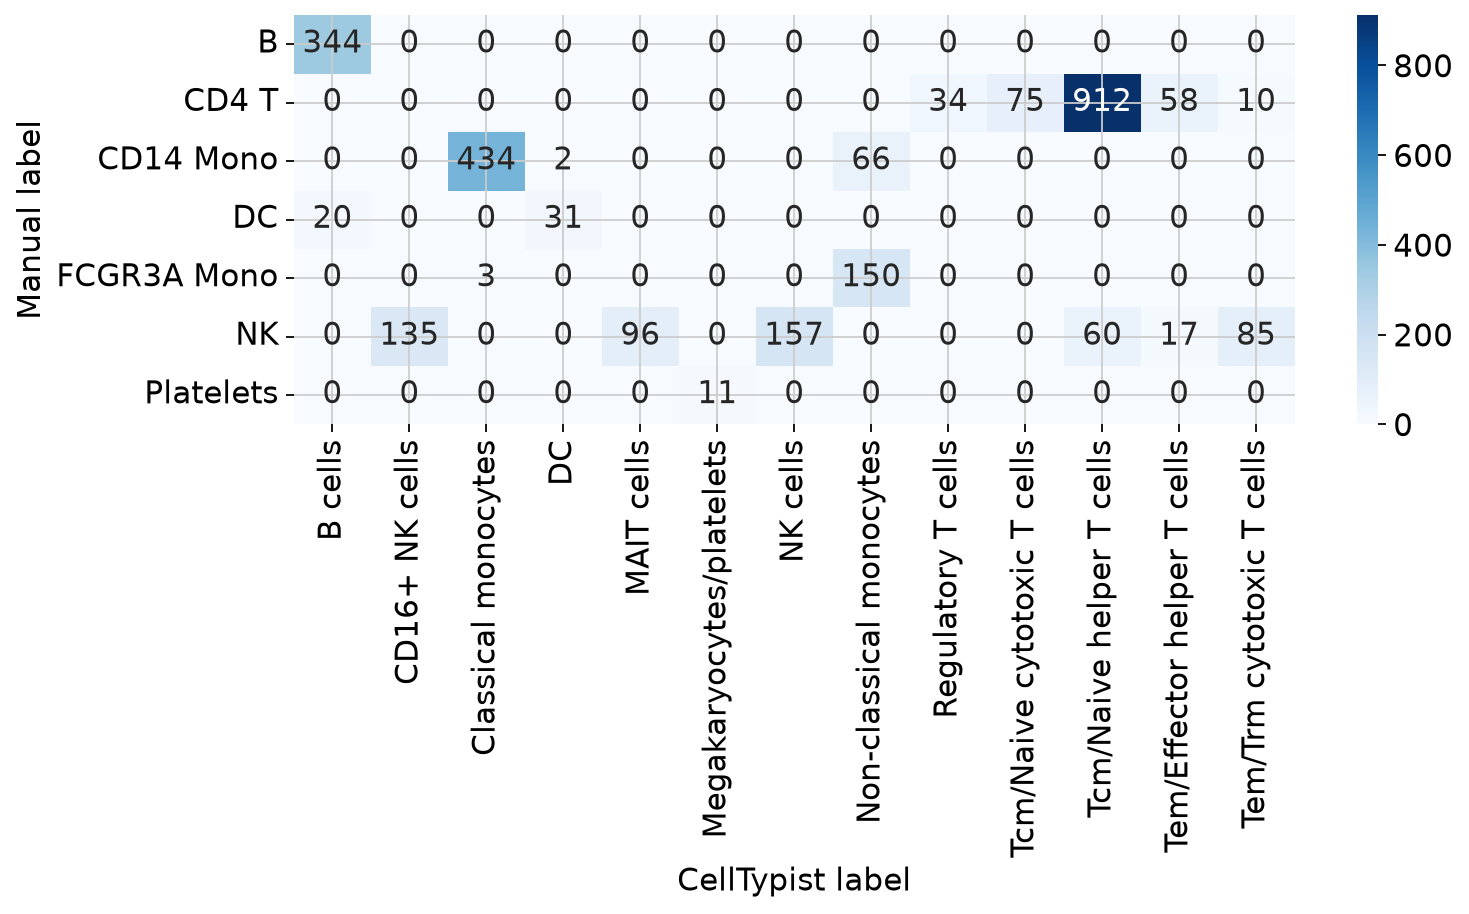

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.heatmap(
    comparison,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("CellTypist label")
plt.ylabel("Manual label")
plt.tight_layout()

plt.savefig(
    results_dir / "manual_vs_celltypist.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [20]:
# Select cells that were manually labelled as NK
nk_cells = adata[adata.obs['manual_label'] == 'NK'].copy()

# Show how CellTypist labelled these manually labelled NK cells
print(nk_cells.obs['majority_voting'].value_counts())

majority_voting
NK cells                       157
CD16+ NK cells                 135
MAIT cells                      96
Tem/Trm cytotoxic T cells       85
Tcm/Naive helper T cells        60
Tem/Effector helper T cells     17
Name: count, dtype: int64


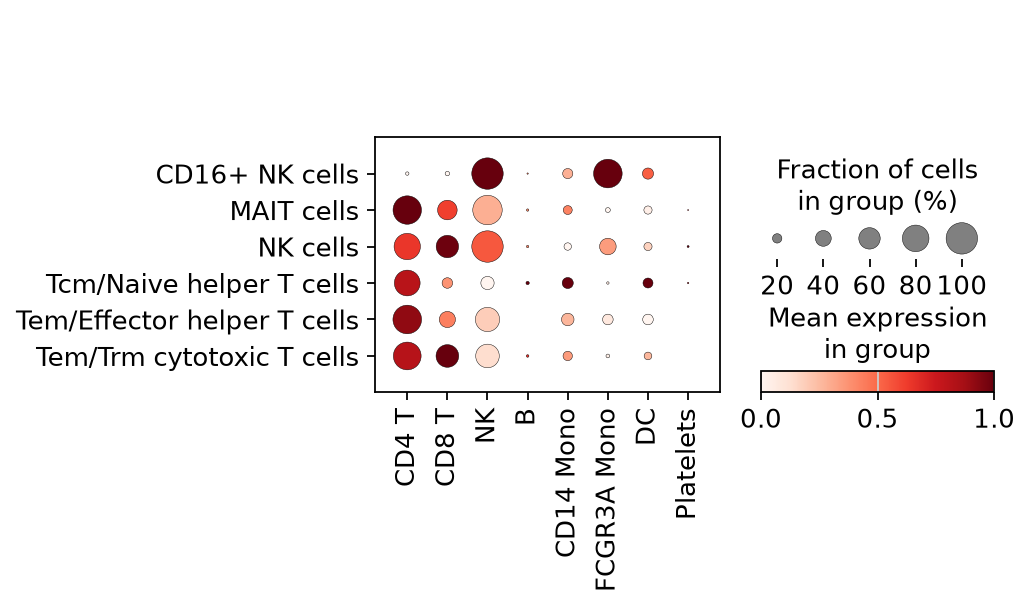

In [27]:
# Marker gene dot plot for the manually labelled NK cells,
# separated by the CellTypist labels.

figure_nk =scanpy.pl.dotplot(
    nk_cells,
    populations,
    groupby='majority_voting',
    standard_scale='var',
    return_fig=True
)
figure_nk.savefig(
    results_dir / "NK_manual_vs_celltypist_dotplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()